# Understand and experiment with DySIB

This notebook follows the actual implementation in `models.py` and `training.py`. It adds a learning workspace without changing the research code or shipped checkpoints.

**Core idea:** learn a small, noisy representation of a video window that retains information about a later window. Then fit a separate supervised probe to measure whether angle and angular velocity can be recovered. Neither latent axis is required to equal a physical variable.

Run sections 1–4 to inspect the representation and computation. Section 5 is an optional small training experiment; section 6 evaluates it. A short run checks the pipeline, not convergence or paper-level accuracy.

The first section needs only NumPy and Matplotlib. Later sections need PyTorch and tqdm. In your chosen notebook environment, install the repository requirements if needed: `%pip install -r requirements.txt`. No cell automatically downloads data or starts training.

## 1. See what the existing model learned

These are **precomputed outputs of the shipped model**, not a new training run. Both panels show the same latent coordinates; only the color changes. Smooth color organization indicates that the representation contains physical information. It does not establish that `z1 = theta` or `z2 = omega`, or by itself prove a globally invertible representation.

`kz=2` specifies two latent coordinates in advance. The separate `kz=8` analysis investigates how many directions are used when the network has more space.

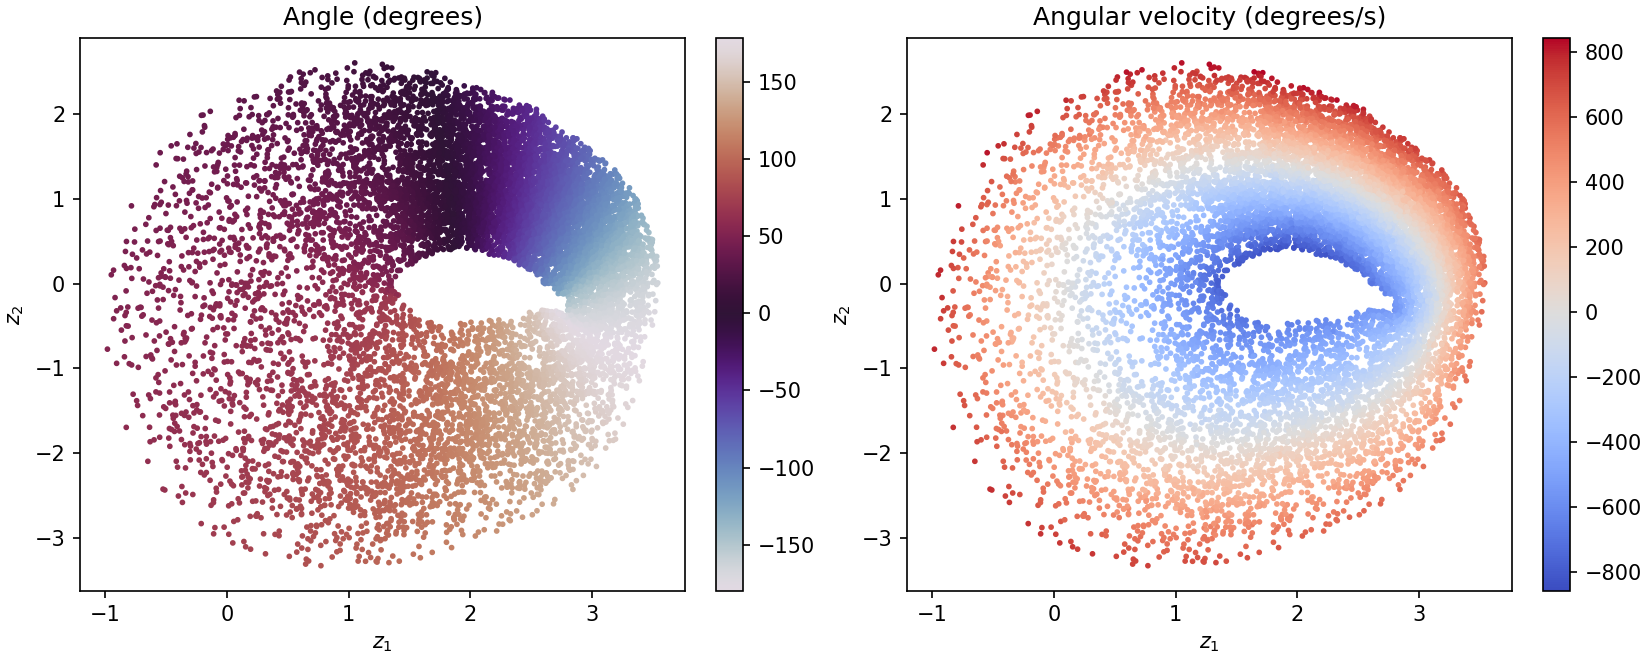

Saved latent array: (69600, 2)


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
assert (ROOT / "models.py").exists(), "Start Jupyter in the DYSIB_Pendulum repository."
with np.load(ROOT / "figure_data/embedding_kz2.npz") as f:
    Z = f["Z"].copy()
    theta_deg = f["theta_deg"].copy()
    omega_dps = f["omega_dps"].copy()

idx = np.random.default_rng(0).choice(len(Z), min(12000, len(Z)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, values, title, cmap in zip(
    axes, (theta_deg, omega_dps),
    ("Angle (degrees)", "Angular velocity (degrees/s)"), ("twilight", "coolwarm")
):
    points = ax.scatter(Z[idx, 0], Z[idx, 1], c=values[idx], s=3, cmap=cmap, rasterized=True)
    ax.set(xlabel="$z_1$", ylabel="$z_2$", title=title)
    fig.colorbar(points, ax=ax)
plt.show()
print("Saved latent array:", Z.shape)

## 2. Understand one training example

Read `FrameDataset.__getitem__` in `models.py` (line 319). With two frames and stride one:

- past `X_t = [frame_t, frame_(t+1)]`
- future `Y_t = [frame_(t+1), frame_(t+2)]`

They overlap. `nF_stride` sets the separation between the two windows, not the spacing of frames inside a window. With 60 frames, there are `60 - 1 - 2 + 1 = 58` pairs per trajectory.

One image generally does not reveal direction of motion. An ordered pair provides motion information. The network is given pixels, not a numerical finite difference or a pendulum equation.

In [ ]:
import torch
from models import DYSIB, FrameDataset, RandomFeatureProber
from training import (train_dysib, encode_dataset, fit_ridge_head,
                      predict_prober, wrapped_theta_rmse_deg_from_cos_sin)

# Toy data: each frame has a single pixel storing its time index.
toy = torch.arange(6, dtype=torch.float32).reshape(1, 6, 1)
pairs = FrameDataset(toy, num_frames=2, nF_stride=1)
for i in range(len(pairs)):
    past, future = pairs[i]
    print(i, "past:", past[:, 0].tolist(), "future:", future[:, 0].tolist())

## 3. Load and inspect the real architecture

`Encoder.forward` (`models.py:62`) applies the **same MLP independently to every frame**:

`784 -> 256 + ReLU -> 256 + ReLU -> 32 + ReLU`

For two frames it concatenates their embeddings to 64 values. Two linear heads map these to a 2D mean and a 2D log variance. A latent sample is `z = mean + exp(logvar/2) * epsilon`.

`DeltaDecoder` (`models.py:77`) is the predictor: `2 -> 64 -> 64 -> 64`, with ReLU after each hidden layer and two output heads. It predicts a latent increment and a conditional log variance. The future mean is `z + delta(z)`. This is a discrete learned step; it is not explicitly a time derivative or a hard-coded pendulum equation.

There is no pixel reconstruction decoder, CNN, RNN, or transformer in this implementation. The encoder's uncertainty and the predictor's uncertainty come from distinct heads.

In [ ]:
checkpoint_path = ROOT / "checkpoints/kz2_nF2_str1_N1000_rep3.pt"
# This is the trusted checkpoint shipped with the repository.
ck = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
p = ck["params"]
model = DYSIB(
    input_dim=int(p["input_dim"]), dz=int(p["ndims"]),
    dzf=int(p.get("dzf", 32)), num_frames=int(p["num_frames"]),
    hidden=int(p.get("hidden", 256)), decoder_hdim=int(p.get("decoder_hdim", 64)),
    gamma=float(p.get("gamma", 0.01)), alpha=float(p.get("alpha", 1.0)),
)
model.load_state_dict(ck["state_dict"])
model.eval()
print("Checkpoint settings:", p)
print(model)
print("Trainable parameters:", sum(v.numel() for v in model.parameters() if v.requires_grad))

## 4. Expand the forward pass and loss

Read `DYSIB.forward` (`models.py:175`) first, then `_nce_info` (`models.py:154`).

For each past sample `i`, the predictor defines a Gaussian over future latent codes. Score every candidate future `j` in the batch with that Gaussian. The correct pair is the diagonal `i=j`; all other entries are contrastive alternatives. InfoNCE rewards identifying the correct future among these candidates.

`loss = gamma * (KL_x + KL_y) - alpha * MI`

The Gaussian KL terms penalize information retained in the noisy code; prediction encourages useful information to survive. Collapsing all codes makes candidates indistinguishable, hurting InfoNCE. Excessive compression can still cause collapse.

The default weights are `gamma=0.01`, `alpha=1`. `MI` is a finite-batch contrastive estimate/bound in natural-log units (nats), not an exact measurement of mutual information. Its maximum is `log(batch_size)`.

The cell below uses **random synthetic images solely to inspect shapes and gradients**. Its loss and MI have no physical interpretation. Both encoder calls and the predictor receive gradients. There is no detached target encoder.

In [ ]:
torch.manual_seed(0)
B = 8
x = torch.rand(B, model.encoder.num_frames, int(p["input_dim"]))
y = torch.rand_like(x)
mx, lx, zx = model.encoder(x)
my, ly, zy = model.encoder(y)
delta, lp = model.delta_decoder(zx)
pred_mean = zx + delta

def gaussian_kl(mean, logvar):
    return (-0.5 * (1 + logvar - mean.square() - logvar.exp())).sum(1).mean()

# axes: past example i, candidate future j, latent coordinate k
scores = -0.5 * (
    (zy[None, :, :] - pred_mean[:, None, :]).square() / lp[:, None, :].exp()
    + lp[:, None, :] + np.log(2 * np.pi)
).sum(-1)
mi = (scores.diagonal() - scores.logsumexp(1) + np.log(B)).mean()
kl = gaussian_kl(mx, lx) + gaussian_kl(my, ly)
loss = model.gamma * kl - model.alpha * mi

# This is exactly the critic used by DYSIB.forward for these latent samples.
assert torch.allclose(mi, model._nce_info(zy, pred_mean, lp), atol=1e-5)
ce = torch.nn.functional.cross_entropy(scores, torch.arange(B))
assert torch.allclose(mi, np.log(B) - ce, atol=1e-5)
print("X, Y:", tuple(x.shape), tuple(y.shape))
print("zx, zy, delta:", tuple(zx.shape), tuple(zy.shape), tuple(delta.shape))
print("Pairwise scores:", tuple(scores.shape), "InfoNCE ceiling:", np.log(B))

model.zero_grad()
loss.backward()  # compute gradients, but do not change the checkpoint weights
print("Encoder gradient norm:", model.encoder.dense1.weight.grad.norm().item())
print("Predictor gradient norm:", model.delta_decoder.mean_head.weight.grad.norm().item())
model.zero_grad()

plt.figure(figsize=(5, 4))
plt.imshow(scores.detach().numpy(), aspect="equal")
plt.xlabel("Candidate future j")
plt.ylabel("Past example i")
plt.title("Gaussian scores on synthetic inputs")
plt.colorbar()
plt.show()

### Sampling during training vs. measuring the learned state

The encoder returns `(mean, logvar, sample)` **even in eval mode**. `model.eval()` does not disable the explicit random draw in `Encoder.forward`. Training and test MI use samples. `encode_dataset` (`training.py:249`) deliberately selects the posterior **mean** for probing and plotting.

For a rollout, encode the initial window once, then repeatedly apply `z_next = z + delta(z)`. Later steps do not receive new observed frames. See `rollout_latent` (`training.py:286`). Errors may accumulate even when one-step prediction looks good.

## 5. Optional: train a small model you can change

First obtain the dataset from a terminal in this repository: `python data.py --all`. The repository describes a roughly 167 MB archive; extraction and preprocessing need additional disk space. The cell below requires the preprocessed cache and does not download it.

Change `RUN_SMALL_EXPERIMENT` to `True` when ready. Defaults use 64 training trajectories, 5 epochs, CPU, and a fixed 256-example held-out evaluation batch. This is an exploratory run, not a reproduction of the paper's 300-epoch result.

The original CLI builds a single evaluation batch from all 200 test trajectories (11,600 windows at the default settings). `_nce_info` creates tensors proportional to `B * B * kz`, so reducing the CLI's training `--batch_size` alone does not fix evaluation memory use. Here both train and evaluation batch sizes are bounded. This changes the contrastive evaluation protocol: do not compare this MI numerically with the paper's full-batch test MI.

Keep `BATCH_SIZE`, `EVAL_SIZE`, `SEED`, and the evaluation selection fixed when comparing models. The seed here controls both initialization and data-order randomness; use multiple seeds for scientific conclusions.

In [ ]:
RUN_SMALL_EXPERIMENT = False
KZ = 2
NUM_FRAMES = 2
STRIDE = 1
GAMMA = 0.01
ALPHA = 1.0
N_TRAIN = 64
EPOCHS = 5
BATCH_SIZE = 256
EVAL_SIZE = 256
SEED = 0
DEVICE = "cpu"

if RUN_SMALL_EXPERIMENT:
    import data as data_mod
    data = data_mod.load(npz_path=ROOT / "data/pendulum_preprocessed.npz", auto=False)
    frames = torch.from_numpy(data["frames"]).float()
    assert 1 <= N_TRAIN <= 1000 and len(frames) >= 1200
    train_ds = FrameDataset(frames[:N_TRAIN], NUM_FRAMES, nF_stride=STRIDE)
    test_ds = FrameDataset(frames[1000:1200], NUM_FRAMES, nF_stride=STRIDE)
    assert len(test_ds) >= EVAL_SIZE
    ids = torch.randperm(len(test_ds), generator=torch.Generator().manual_seed(123))[:EVAL_SIZE]
    x_test = torch.stack([test_ds[int(i)][0] for i in ids]).to(DEVICE)
    y_test = torch.stack([test_ds[int(i)][1] for i in ids]).to(DEVICE)

    torch.manual_seed(SEED)
    np.random.seed(SEED)
    loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    experiment = DYSIB(input_dim=frames.shape[-1], dz=KZ, num_frames=NUM_FRAMES,
                       gamma=GAMMA, alpha=ALPHA).to(DEVICE)
    experiment, history = train_dysib(experiment, loader, x_test, y_test,
                                      epochs=EPOCHS, lr=1e-4, device=DEVICE)
    for key in ("train_loss", "train_kl", "train_mi", "test_mi"):
        plt.plot(history[key], label=key)
    plt.xlabel("Epoch index")
    plt.legend()
    plt.show()
else:
    print("Training is off. Read the cell above, obtain data, then enable the toggle.")

## 6. Check whether physical variables can be recovered

The prober is trained **after** representation learning. It receives frozen latent means and true physical labels. There is no gradient from the probe back to DySIB.

The primary probe in this repository is a fixed random projection to 512 features, Softplus, and a fitted linear head. It is nonlinear as a function of `z`, even though its final head is linear. `fit_ridge_head` solves ridge regression directly. Its `alpha=1e-3` is ridge regularization and is unrelated to DySIB's MI weight also named `alpha`.

Angle is learned as `[cos(theta), sin(theta)]` and recovered with `atan2`. Wrapped error prevents a tiny crossing of the -180/180 degree boundary from appearing as a 360 degree error. Angular velocity is a separate scalar regression.

**Time alignment:** the analysis associates each window with the physical labels at its **first frame**, not its last frame or midpoint. This matches `_fvars_flat` in `precompute_figure_data.py:130`. Preserve this alignment when adding experiments.

In [ ]:
if RUN_SMALL_EXPERIMENT:
    z_train, numD = encode_dataset(experiment, frames[:N_TRAIN], NUM_FRAMES,
                                  nF_stride=STRIDE, device=DEVICE)
    z_test, test_numD = encode_dataset(experiment, frames[1000:1200], NUM_FRAMES,
                                      nF_stride=STRIDE, device=DEVICE)
    assert test_numD == numD
    theta_train = torch.from_numpy(data["theta"][:N_TRAIN, :numD].reshape(-1)).float()
    theta_test = torch.from_numpy(data["theta"][1000:1200, :numD].reshape(-1)).float()
    omega_train = torch.from_numpy(data["vel_theta"][:N_TRAIN, :numD].reshape(-1, 1)).float()
    omega_test = torch.from_numpy(data["vel_theta"][1000:1200, :numD].reshape(-1, 1)).float()

    torch.manual_seed(123)
    angle_probe = RandomFeatureProber(KZ, output_dim=2).to(DEVICE)
    speed_probe = RandomFeatureProber(KZ, output_dim=1).to(DEVICE)
    fit_ridge_head(angle_probe, z_train, torch.stack((theta_train.cos(), theta_train.sin()), 1),
                   alpha=1e-3, device=DEVICE)
    fit_ridge_head(speed_probe, z_train, omega_train, alpha=1e-3, device=DEVICE)
    angle_xy = predict_prober(angle_probe, z_test, device=DEVICE)
    speed = predict_prober(speed_probe, z_test, device=DEVICE)
    print("Test angle RMSE (degrees):", wrapped_theta_rmse_deg_from_cos_sin(angle_xy, theta_test))
    print("Test angular velocity RMSE (rad/s):", (speed - omega_test).square().mean().sqrt().item())

## Experiments to try, one change at a time

| Change | Question | What to inspect |
|---|---|---|
| `NUM_FRAMES: 2 -> 1` | How much does visible motion help? | Angular-velocity probe RMSE, not just MI |
| `KZ: 2 -> 1` | Is one coordinate enough across these trajectories? | Both physical probe errors |
| `KZ: 2 -> 8` | Does extra capacity improve prediction or merely enlarge the representation? | Probe errors and latent dimension analysis |
| `GAMMA: 0.01 -> 0.1` | What information is lost with stronger compression? | MI, raw KL, probe errors, collapsed latents |
| `STRIDE: 1 -> 2` | What changes when the windows no longer overlap? | Probe errors and rollout quality at matched physical horizons |

These are hypotheses to investigate, not promised outcomes. Recreate and retrain the model when changing its architecture. Train longer after a successful pipeline check, and compare several random seeds.

**Useful source-reading order:** `FrameDataset` -> `Encoder.forward` -> `DeltaDecoder.forward` -> `DYSIB.forward` -> `_nce_info` -> `train_dysib` -> probing and rollout.

**Other implementation details to remember:**

- `train_kl` is already multiplied by gamma; divide by gamma to inspect the unweighted KL when gamma is nonzero.
- Calling the model returns `(loss, weighted_KL, weighted_MI, raw_MI)`.
- The CLI exposes `--kz`, `--num_frames`, `--nF_stride`, `--gamma`, `--alpha`, and training settings. Encoder width, per-frame feature size, and predictor width are constructor arguments, not CLI flags.
- `precompute_figure_data._load_checkpoint` hard-codes widths 256/32/64. Changing them requires updating that loader too; the checkpoint-loading cell above reads those settings from metadata.
- `reproduce_figures.ipynb` plots cached arrays. Editing or retraining a model does not automatically update those arrays. The small experiment here computes its own codes and probes directly.
- Some sweep CSVs rely on internal HDF5 source files that are not shipped. They cannot all be recreated from the four checkpoints alone.
- The original reproduction notebook names an `MI_estimation` kernel. If it is unavailable, select your installed Python kernel with the required packages.

This notebook does not save new model weights automatically. The pretrained model inspected above is separate from `experiment`, the newly trained model.